In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

np.random.seed(3)
city = "Одеса"
base_temp = 11.5  # середньорічна температура
amplitude = 13.0  # сезонна амплітуда
base_consumption = 3100  # базове споживання, МВт·год
k = 35  # нахил: МВт·год на кожен градус нижче середньої
noise_sd = 60  # рівень шуму споживання, МВт·год

months = np.arange(1, 13)
temp = base_temp + amplitude * np.cos((months - 7) / 12 * 2 * np.pi)
temp = np.round(temp + np.random.normal(0, 0.5, size=12), 1)

consumption = base_consumption - k * (temp - base_temp) + np.random.normal(0, noise_sd, size=12)
consumption = np.round(consumption, 0)

city_data = pd.DataFrame(
    {
        "місяць": months,
        "температура": temp,
        "споживання_МВтгод": consumption,
    }
)

print(f"Місто: {city}")
print(city_data)

Місто: Одеса
    місяць  температура  споживання_МВтгод
0        1         -0.6             3576.0
1        2          0.5             3588.0
2        3          5.0             3331.0
3        4         10.6             3107.0
4        5         17.9             2843.0
5        6         22.6             2619.0
6        7         24.5             2704.0
7        8         22.4             2652.0
8        9         18.0             2801.0
9       10         11.3             3095.0
10      11          4.3             3441.0
11      12          0.7             3492.0


In [2]:
b, a = np.polyfit(city_data["температура"], city_data["споживання_МВтгод"], 1)

print(f"Підібрана модель: споживання ≈ {a:.1f} + ({b:.1f}) · температура")

city_data["передбачення"] = a + b * city_data["температура"]

Підібрана модель: споживання ≈ 3553.8 + (-39.3) · температура


In [3]:
city_data["залишок"] = city_data["споживання_МВтгод"] - city_data["передбачення"]

print(city_data[["місяць", "температура", "споживання_МВтгод", "передбачення", "залишок"]])

residuals = city_data["залишок"]
ss_res = (residuals**2).sum()
ss_tot = ((city_data["споживання_МВтгод"] - city_data["споживання_МВтгод"].mean()) ** 2).sum()
r_squared = 1 - ss_res / ss_tot

print(f"\nКоефіцієнт детермінації R^2 = {r_squared:.4f}")

    місяць  температура  споживання_МВтгод  передбачення     залишок
0        1         -0.6             3576.0   3577.402413   -1.402413
1        2          0.5             3588.0   3534.135018   53.864982
2        3          5.0             3331.0   3357.132038  -26.132038
3        4         10.6             3107.0   3136.861663  -29.861663
4        5         17.9             2843.0   2849.723495   -6.723495
5        6         22.6             2619.0   2664.853716  -45.853716
6        7         24.5             2704.0   2590.119125  113.880875
7        8         22.4             2652.0   2672.720515  -20.720515
8        9         18.0             2801.0   2845.790096  -44.790096
9       10         11.3             3095.0   3109.327866  -14.327866
10      11          4.3             3441.0   3384.665835   56.334165
11      12          0.7             3492.0   3526.268219  -34.268219

Коефіцієнт детермінації R^2 = 0.9827


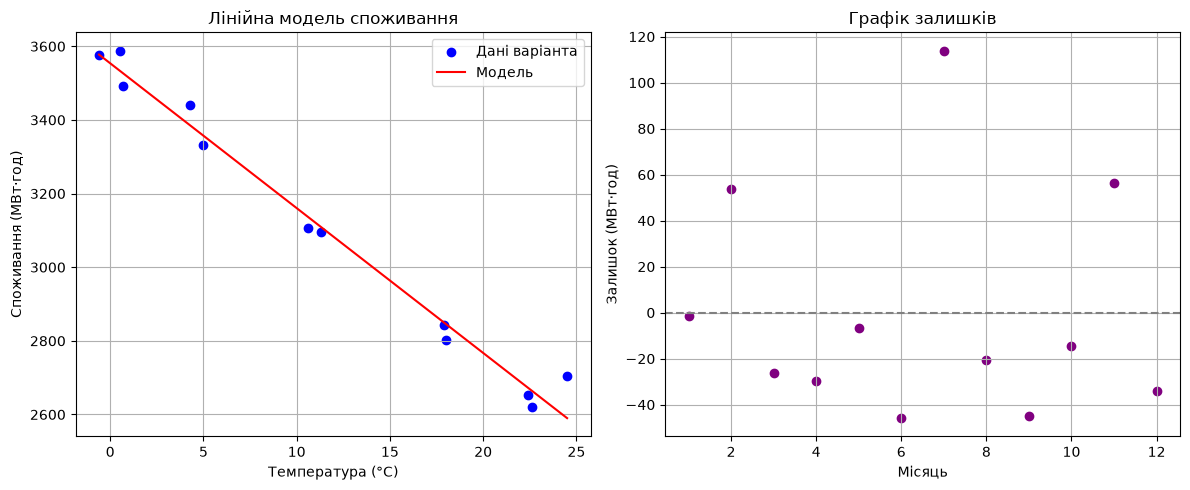

In [4]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(city_data["температура"], city_data["споживання_МВтгод"], color="blue", label="Дані варіанта")
temp_sorted = np.sort(city_data["температура"])
plt.plot(temp_sorted, a + b * temp_sorted, color="red", label="Модель")
plt.xlabel("Температура (°C)")
plt.ylabel("Споживання (МВт·год)")
plt.title("Лінійна модель споживання")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.axhline(0, color="gray", linestyle="--")
plt.scatter(city_data["місяць"], city_data["залишок"], color="purple")
plt.xlabel("Місяць")
plt.ylabel("Залишок (МВт·год)")
plt.title("Графік залишків")
plt.grid(True)

plt.tight_layout()
plt.show()

### Markdown-клітинка: Відповіді на контрольні питання

#### 1. Чітке розмежування верифікації й валідації на прикладі нашої моделі (Варіант 3, Одеса)

* **Верифікація** стосується виключно коректності програмної реалізації та обчислень усередині нашої моделі. Для нашого розв'язку це означає перевірку того, чи правильно функція `np.polyfit` або формула `a + b * температура` обчислює передбачення без математичних чи синтаксичних помилок у коді. Наприклад, якщо ми візьмемо місяць із температурою $temp = 2.0$ °C і вручну підставимо його у знайдені параметри ($a$ та $b$), отримане значення має повністю збігтися зі значенням у стовпчику `передбачення` нашого DataFrame. Це виконується внутрішньо, без звернення до «реальних» виміряних даних споживання з лічильників.
* **Валідація** оцінює відповідність самої концепції моделі реальному світу. Для нашої моделі це перевірка того, чи адекватно проста лінійна залежність споживання від температури описує реальні енерговитрати міста. Для чесної валідації наявних 12 місяців недостатню, оскільки вони вже використані для підбору коефіцієнтів методом найменших квадратів. Повноцінна валідація вимагає залучення нових незалежних даних (наприклад, спостережень за наступний рік), які модель «не бачила» під час навчання.

---

#### 2. Незалежні ознаки класифікації моделі та чому вони не суперечать одна одній

Наша модель класифікується за трьома незалежними осями:

1. **Стохастична** (за наявністю невизначеності/шуму в даних): детермінована формула комбінується з випадковим відхиленням (`noise_sd`).
2. **Статична** (за характером зв'язку в часі): передбачення розраховується за температурою поточного місяця без врахування попередньої преісторії чи лагів.
3. **Описово-прогнозна / жодна з трьох** (за метою моделювання): вона не є балансовою чи оптимізаційною, а слугує для статистичного опису та прогнозу.

* **Чому вони не суперечать?** Тому що ці ознаки відповідають на абсолютно **різні питання** про систему: перша характеризує наявність випадкового шуму, друга — врахування динаміки в часі, а третя — мету створення моделі (опис зв'язку замість оптимізації чи балансу).

---

#### 3. Що показує $R^2$ і чи доводить він придатність для екстраполяції?

* Отримане значення **коефіцієнта детермінації ($R^2$)** показує, яка частка дисперсії місячного споживання електроенергії пояснюється зміною середньомісячної температури в межах наявних 12 місяців вибірки.
* **Чи доводить це придатність для екстраполяції?** Ні, високе значення $R^2$ саме по собі **не гарантує** правильності моделі за межами спостережуваного діапазону температур. Якщо місто зіткнеться з аномальними морозами (наприклад, нижче мінімальної температури у вибірці) або сильну спеку (коли вмикаються масово кондиціонери, створюючи нелінійне зростання навантаження), проста лінійна екстраполяція почне давати серйозні похибки.

---

#### 4. Чому структура залишків інформативніша за сумарну величину відхилень?

* Сумарна величина відхилень (або просте середнє) може бути близькою до нуля через взаємокомпенсацію додатних і від'ємних похибок.
* **Структура залишків** (наявність чи відсутність систематичного тренду або патерну на графіку) показує, чи є в нашій моделі системні архітектурні похибки. Якщо всі зимові місяці лежать вище лінії моделі, а літні — нижче (утворюючи дугоподібну закономірність), це чіткий сигнал, що лінійна функція спрощує реальну фізику процесу (наприклад, не враховує нелінійне охолодження чи кондиціювання). Випадковий розкид залишків навколо нуля без систематичних трендів підтверджує саме адекватність обраної структури.